# Lecture Examples

In [ ]:
import polars as pl
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

from skimage.io import imread
from skimage.transform import resize
import imageio

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [35]:
# Load the image
image = imread('data/pishi.jpg')
image_resized = resize(image, (200, 200))
pixels = image_resized.reshape(-1, 3)

frames = []

for clusters in range(2, 30):
    # K-Means Clustering
    kmeans = KMeans(n_clusters=clusters, random_state=42)
    kmeans.fit(pixels)
    compressed_pixels = kmeans.cluster_centers_[kmeans.labels_]
    compressed_image = compressed_pixels.reshape(image_resized.shape)
    
    # Rotate images
    image_resized_rotated = np.rot90(image_resized, k=-1)  
    compressed_image_rotated = np.rot90(compressed_image, k=-1) 
    
    # Visualize
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(image_resized_rotated)
    ax[0].set_title('Original Image')
    ax[0].axis('off')
    
    ax[1].imshow(compressed_image_rotated)
    ax[1].set_title('Compressed Image')
    ax[1].axis('off')
    
    plt.suptitle(f"Number of Clusters = {clusters}")
    
    # Save each frame as an image
    filename = f"img_output/clustering_comparison_{clusters}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight') 
    frames.append(filename) 
    plt.close()  

# Create GIF
with imageio.get_writer('clustering_animation.gif', mode='I', duration=2, loop=0) as writer:
    for frame in frames:
        image = imageio.imread(frame)
        writer.append_data(image)

print("GIF saved as 'clustering_animation.gif'")

/tmp/ipykernel_157/2309398690.py:41: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(frame)


GIF saved as 'clustering_animation.gif'


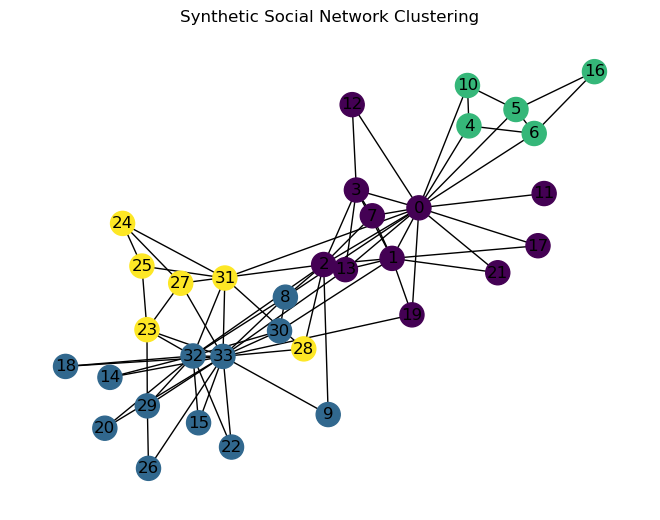

In [40]:
import networkx as nx
from sklearn.cluster import SpectralClustering

# Generate synthetic social network graph
G = nx.karate_club_graph()  # Example graph
adj_matrix = nx.adjacency_matrix(G)  # Adjacency matrix as a sparse matrix
adj_matrix_dense = adj_matrix.toarray()  # Convert sparse matrix to dense numpy array

# Clustering
spectral = SpectralClustering(n_clusters=4, affinity='precomputed', random_state=42)
clusters = spectral.fit_predict(adj_matrix_dense)  # Use dense adjacency matrix

# Visualize clusters
pos = nx.spring_layout(G)
nx.draw(G, pos, node_color=clusters, with_labels=True, cmap='viridis')
plt.title("Synthetic Social Network Clustering")
plt.savefig("img_output/SN_Clustering")
plt.show()

In [ ]:
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load the GlobalTemperatures dataset
data = pl.read_csv('data/GlobalTemperatures.csv')

data = data.with_columns(pl.col('dt').str.to_date().dt.year().alias('Year'))
avg_temp_by_year = (
    data.group_by('Year')
        .agg(pl.col('LandAverageTemperature').mean())
        .sort('Year')
)

# Synthetic Latitude and Longitude
np.random.seed(42)
avg_temp_by_year = avg_temp_by_year.with_columns(
    pl.Series('Latitude', np.random.uniform(-90, 90, size=avg_temp_by_year.height)),
    pl.Series('Longitude', np.random.uniform(-180, 180, size=avg_temp_by_year.height)),
)

# Standardize the temperature data
scaler = StandardScaler()
avg_temp_by_year = avg_temp_by_year.with_columns(
    pl.Series('ScaledTemp', scaler.fit_transform(avg_temp_by_year[['LandAverageTemperature']]).ravel())
)

# Apply K-Means clustering
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
avg_temp_by_year = avg_temp_by_year.with_columns(
    pl.Series('Cluster', kmeans.fit_predict(avg_temp_by_year[['ScaledTemp']]))
)

# Convert to GeoDataFrame for mapping
gdf = gpd.GeoDataFrame(
    avg_temp_by_year.to_pandas(),
    geometry=gpd.points_from_xy(
        avg_temp_by_year['Longitude'], avg_temp_by_year['Latitude']
    ),
)
gdf.set_crs(epsg=4326, inplace=True)  # Use WGS84 projection

# Load a world map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Plot the map
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world.plot(ax=ax, color='lightgrey', edgecolor='black', alpha=0.7)

gdf.plot(
    ax=ax,
    column='Cluster',
    cmap='viridis',
    markersize=50,
    legend=True,
    alpha=0.8
)

# Add titles and labels
plt.title("Global Average Temperature Clusters (Yearly)", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()